# Posterior parameter recovery


In [2]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.ticker import FormatStrFormatter, MaxNLocator
from matplotlib_inline.backend_inline import set_matplotlib_formats
import numpy as np
import pandas as pd
import scienceplots  # noqa: F401 -- registers the science style
from IPython.display import Markdown, display
from tqdm.auto import tqdm

plt.style.use("science")
set_matplotlib_formats("svg")

FIGURE_STYLE = {
    "font.size": 17,
    "axes.titlesize": 20,
    "axes.labelsize": 18,
    "axes.titlepad": 10,
    "axes.labelpad": 8,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 15,
    "legend.title_fontsize": 16,
    "figure.titlesize": 22,
    "lines.linewidth": 2.0,
}
plt.rcParams.update(FIGURE_STYLE)

PARAMETER_LABELS = {
    "outside_optimism": "Outside optimism",
    "exploration": "Exploration",
    "visibility_distance": "Visibility distance",
}
PARAMETER_COLORS = ("#4477AA", "#EE6677", "#228833")


def find_project_root(start=Path.cwd()):
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (
            candidate / "network_creation"
        ).is_dir():
            return candidate
    raise RuntimeError("Could not locate the network-creation project root.")


project_root = find_project_root()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from network_creation.model_inversion import load_posterior_artifact
from network_creation.model_inversion.diagnostics import (
    load_diagnostic_data,
    marginal_sbc_ranks,
    plot_sbc_ranks,
)
from network_creation.model_inversion.posterior import (
    category_probabilities,
    validate_discrete_theta_samples,
)
from network_creation.model_inversion.recovery_plots import (
    plot_posterior_ridgelines,
)

## 1. Data loading


In [3]:
ARTIFACT_DIR = "mnpe-20260806T171531Z"

N_DIAGNOSTIC_CASES = None
N_POSTERIOR_SAMPLES_PER_CASE = 2**8
POSTERIOR_SAMPLE_CHUNK_SIZE = 256
MAX_SAMPLING_BATCH_SIZE = max(1, 100_000 // POSTERIOR_SAMPLE_CHUNK_SIZE)
MAX_SAMPLING_TIME_SECONDS = 300
RIDGELINE_CASES = 50
MAP_HISTOGRAM_BINS = 40
SEED = 42
DEVICE = "cpu"

In [4]:
def resolve_artifact_dir(raw_path):
    path = Path(raw_path).expanduser()
    candidates = (
        (path,)
        if path.is_absolute()
        else (
            project_root / "artifacts" / "model_inversion" / path,
            project_root / path,
            Path.cwd() / path,
        )
    )
    for candidate in candidates:
        if candidate.is_dir():
            return candidate.resolve()
    searched = "\n".join(f"- {candidate}" for candidate in candidates)
    raise FileNotFoundError(f"Posterior artifact not found. Searched:\n{searched}")

In [5]:
artifact_dir = resolve_artifact_dir(ARTIFACT_DIR)
artifact = load_posterior_artifact(artifact_dir)
metadata = artifact.metadata
dataset_metadata = metadata.dataset
diagnostic_data = load_diagnostic_data(artifact)
prior_samples = artifact.prior_samples
theta_names = list(artifact.theta_order)

diagnostic_input_values = artifact.input_values_from_x(diagnostic_data.x)
if "n_agents" not in diagnostic_input_values:
    raise ValueError(
        "The recovery views require n_agents in the artifact inputs."
    )
diagnostic_n_agents = np.asarray(
    diagnostic_input_values["n_agents"],
    dtype=np.float32,
)
if diagnostic_n_agents.shape != (diagnostic_data.theta.shape[0],):
    raise ValueError("Decoded n_agents values must align with diagnostic rows.")

display(
    {
        "artifact_dir": (
            str(artifact_dir.relative_to(project_root))
            if artifact_dir.is_relative_to(project_root)
            else str(artifact_dir)
        ),
        "sbi_method": metadata.sbi.method,
        "posterior_type": type(artifact.posterior).__name__,
        "theta_order": theta_names,
        "continuous_theta_names": list(artifact.continuous_theta_names),
        "discrete_theta_names": list(artifact.discrete_theta_names),
        "x_shape": tuple(dataset_metadata.x_event_shape),
        "continuous_input_names": list(artifact.continuous_input_names),
        "discrete_input_names": list(artifact.discrete_input_names),
        "diagnostic_rows": int(diagnostic_data.theta.shape[0]),
        "stored_prior_samples": int(prior_samples.shape[0]),
    }
)

{'artifact_dir': 'artifacts/model_inversion/mnpe-20260806T171531Z',
 'sbi_method': 'MNPE',
 'posterior_type': 'DirectPosterior',
 'theta_order': ['outside_optimism', 'exploration', 'visibility_distance'],
 'continuous_theta_names': ['outside_optimism', 'exploration'],
 'discrete_theta_names': ['visibility_distance'],
 'x_shape': (601, 6),
 'continuous_input_names': [],
 'discrete_input_names': ['n_agents'],
 'diagnostic_rows': 3840,
 'stored_prior_samples': 4096}

## 2. SBI fit quality


### Learning curve


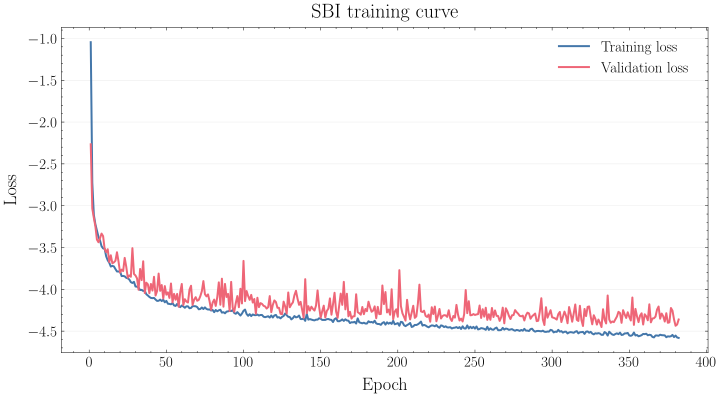

,metric,n_epochs,first,last,best
0,train_loss,382,-1.045024,-4.581055,-4.581055
1,validation_loss,382,-2.265757,-4.360932,-4.451131


In [6]:
training_metrics_path = artifact_dir / metadata.sbi.training_metrics_file
training_metrics = json.loads(training_metrics_path.read_text(encoding="utf-8"))
loss_curves = {
    name: np.asarray(training_metrics[name], dtype=np.float64)
    for name in ("train_loss", "validation_loss")
    if training_metrics.get(name)
}

if loss_curves:
    curve_labels = {
        "train_loss": "Training loss",
        "validation_loss": "Validation loss",
    }
    fig, ax = plt.subplots(figsize=(10, 5.5), layout="constrained")
    for color, (name, values) in zip(
        PARAMETER_COLORS,
        loss_curves.items(),
        strict=False,
    ):
        ax.plot(
            np.arange(1, len(values) + 1),
            values,
            color=color,
            label=curve_labels.get(name, name.replace("_", " ")),
        )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.set_title("SBI training curve")
    ax.legend(frameon=False)
    ax.grid(axis="y", alpha=0.25)
    plt.show()
else:
    display(Markdown("No training or validation loss curves were stored."))

loss_summary = [
    {
        "metric": name,
        "n_epochs": int(values.size),
        "first": float(values[0]),
        "last": float(values[-1]),
        "best": float(values.min()),
    }
    for name, values in loss_curves.items()
]
display(pd.DataFrame(loss_summary))

### Held-out posterior samples


In [7]:
def stratified_sample_indices(group_values, sample_size, rng):
    groups = np.asarray(group_values)
    if sample_size is None:
        sample_size = int(groups.size)
    else:
        sample_size = min(int(sample_size), int(groups.size))
    if sample_size <= 0:
        raise ValueError(
            "sample_size and the available diagnostic rows must be positive."
        )

    _, group_indices = np.unique(groups, return_inverse=True)
    available_counts = np.bincount(group_indices)
    exact_counts = available_counts * sample_size / groups.size
    selected_counts = np.floor(exact_counts).astype(int)
    remainder = sample_size - int(selected_counts.sum())
    if remainder:
        priority = np.argsort(-(exact_counts - selected_counts))
        selected_counts[priority[:remainder]] += 1

    selected = np.concatenate(
        [
            rng.choice(
                np.flatnonzero(group_indices == group_index),
                size=count,
                replace=False,
            )
            for group_index, count in enumerate(selected_counts)
            if count
        ]
    ).astype(np.int64)
    rng.shuffle(selected)
    return selected

In [8]:
rng = np.random.default_rng(SEED)
diagnostic_indices = stratified_sample_indices(
    diagnostic_n_agents,
    N_DIAGNOSTIC_CASES,
    rng,
)
diagnostic_theta = validate_discrete_theta_samples(
    diagnostic_data.theta[diagnostic_indices],
    theta_names=artifact.theta_order,
    discrete_theta_values=artifact.schema.discrete_theta_values,
)
diagnostic_x = diagnostic_data.x[diagnostic_indices]
selected_n_agents = diagnostic_n_agents[diagnostic_indices]
n_agent_values = np.unique(selected_n_agents)

chunks_per_case = (
    N_POSTERIOR_SAMPLES_PER_CASE + POSTERIOR_SAMPLE_CHUNK_SIZE - 1
) // POSTERIOR_SAMPLE_CHUNK_SIZE
posterior_samples_by_case = []
with tqdm(
    diagnostic_x,
    desc="Sampling diagnostic posteriors",
    unit="case",
) as cases:
    for case_index, x in enumerate(cases):
        samples = artifact.sample_cases(
            x,
            num_samples=N_POSTERIOR_SAMPLES_PER_CASE,
            seed=SEED + case_index * chunks_per_case,
            device=DEVICE,
            max_samples_per_call=POSTERIOR_SAMPLE_CHUNK_SIZE,
            max_sampling_batch_size=MAX_SAMPLING_BATCH_SIZE,
            max_sampling_time=MAX_SAMPLING_TIME_SECONDS,
            show_progress_bars=False,
        )[0]
        posterior_samples_by_case.append(samples)

diagnostic_posterior_samples = np.stack(
    posterior_samples_by_case,
    axis=0,
).astype(np.float32, copy=False)

group_rows = [
    {
        "n_agents": int(value),
        "available_cases": int(
            np.count_nonzero(diagnostic_n_agents == value)
        ),
        "selected_cases": int(np.count_nonzero(selected_n_agents == value)),
    }
    for value in n_agent_values
]
display(
    {
        "posterior_sample_shape": tuple(diagnostic_posterior_samples.shape),
        "requested_diagnostic_cases": N_DIAGNOSTIC_CASES,
        "available_diagnostic_cases": int(diagnostic_data.theta.shape[0]),
    }
)
display(pd.DataFrame(group_rows))

Sampling diagnostic posteriors:   0%|          | 0/3840 [00:00<?, ?case/s]

{'posterior_sample_shape': (3840, 256, 3),
 'requested_diagnostic_cases': None,
 'available_diagnostic_cases': 3840}

,n_agents,available_cases,selected_cases
0,10,1280,1280
1,50,1280,1280
2,100,1280,1280


### Simulation-based calibration


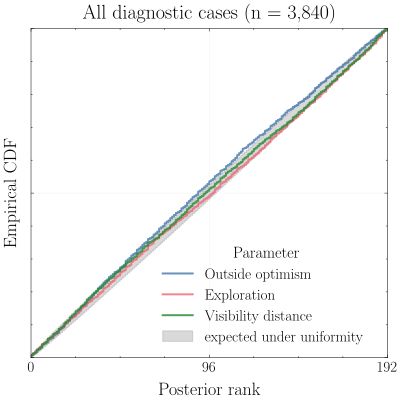

In [9]:
sbc_parameter_labels = [
    PARAMETER_LABELS.get(name, name.replace("_", " "))
    for name in theta_names
]


def style_sbc_axis(ax, *, title, show_legend):
    ax.set_title(title)
    ax.set_xlabel("Posterior rank")
    ax.set_ylabel("Empirical CDF")
    ax.grid(alpha=0.2)
    legend = ax.get_legend()
    if legend is None:
        return
    if not show_legend:
        legend.remove()
        return
    legend.set_title("Parameter")
    legend.set_frame_on(False)


ranks = marginal_sbc_ranks(
    artifact,
    diagnostic_posterior_samples,
    diagnostic_theta,
    seed=SEED,
)
sbc_data = {
    "ranks": ranks,
    "num_posterior_samples": N_POSTERIOR_SAMPLES_PER_CASE,
}
fig, ax = plot_sbc_ranks(
    artifact,
    sbc_data,
    parameter_labels=sbc_parameter_labels,
    colors=list(PARAMETER_COLORS),
    figsize=(6, 6),
    legend_kwargs={"loc": "lower right", "frameon": False},
)
style_sbc_axis(
    ax,
    title=f"All diagnostic cases (n = {len(diagnostic_theta):,})",
    show_legend=True,
)
fig.tight_layout()
plt.show()

In [16]:
run_id = artifact_dir.name
figure_output_dir = project_root / "artifacts" / "figures" / run_id
figure_output_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_output_dir / "sbc_curve.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print(f"Saved: {figure_path.relative_to(project_root)}")

Saved: artifacts/figures/mnpe-20260806T171531Z/sbc_curve.pdf


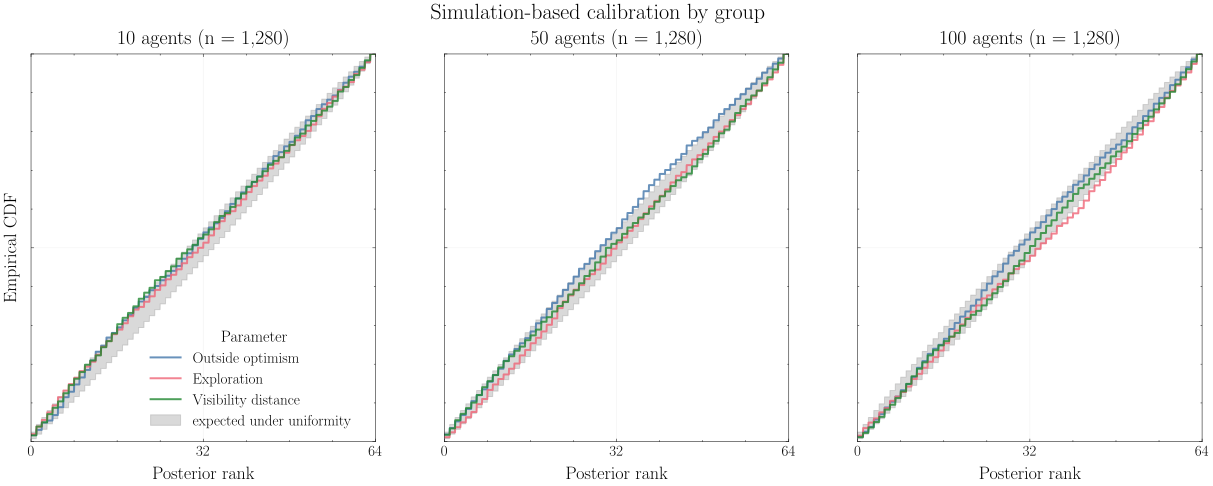

In [10]:
fig, axes = plt.subplots(
    1,
    len(n_agent_values),
    figsize=(7 * len(n_agent_values), 7),
    sharex=True,
    sharey=True,
    squeeze=False,
)
for column_index, n_agents_value in enumerate(n_agent_values):
    group_mask = selected_n_agents == n_agents_value
    n_group_cases = int(group_mask.sum())
    group_sbc_data = {
        "ranks": ranks[group_mask],
        "num_posterior_samples": N_POSTERIOR_SAMPLES_PER_CASE,
    }
    ax = axes[0, column_index]
    plot_sbc_ranks(
        artifact,
        group_sbc_data,
        parameter_labels=sbc_parameter_labels,
        colors=list(PARAMETER_COLORS),
        fig=fig,
        ax=ax,
        legend_kwargs={"loc": "lower right", "frameon": False},
    )
    style_sbc_axis(
        ax,
        title=f"{n_agents_value:g} agents (n = {n_group_cases:,})",
        show_legend=column_index == 0,
    )
    if column_index != 0:
        ax.set_ylabel("")

fig.suptitle("Simulation-based calibration by group")
plt.show()

In [ ]:
run_id = artifact_dir.name
figure_output_dir = project_root / "artifacts" / "figures" / run_id
figure_output_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_output_dir / "sbc_curves_by_n_agents.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print(f"Saved: {figure_path.relative_to(project_root)}")

## 3. Parameter recovery

Ridgelines compare each held-out true parameter with its posterior marginal. Cases are randomly ordered by the stratified sampling step above; each panel then sorts them by the true value for readability.


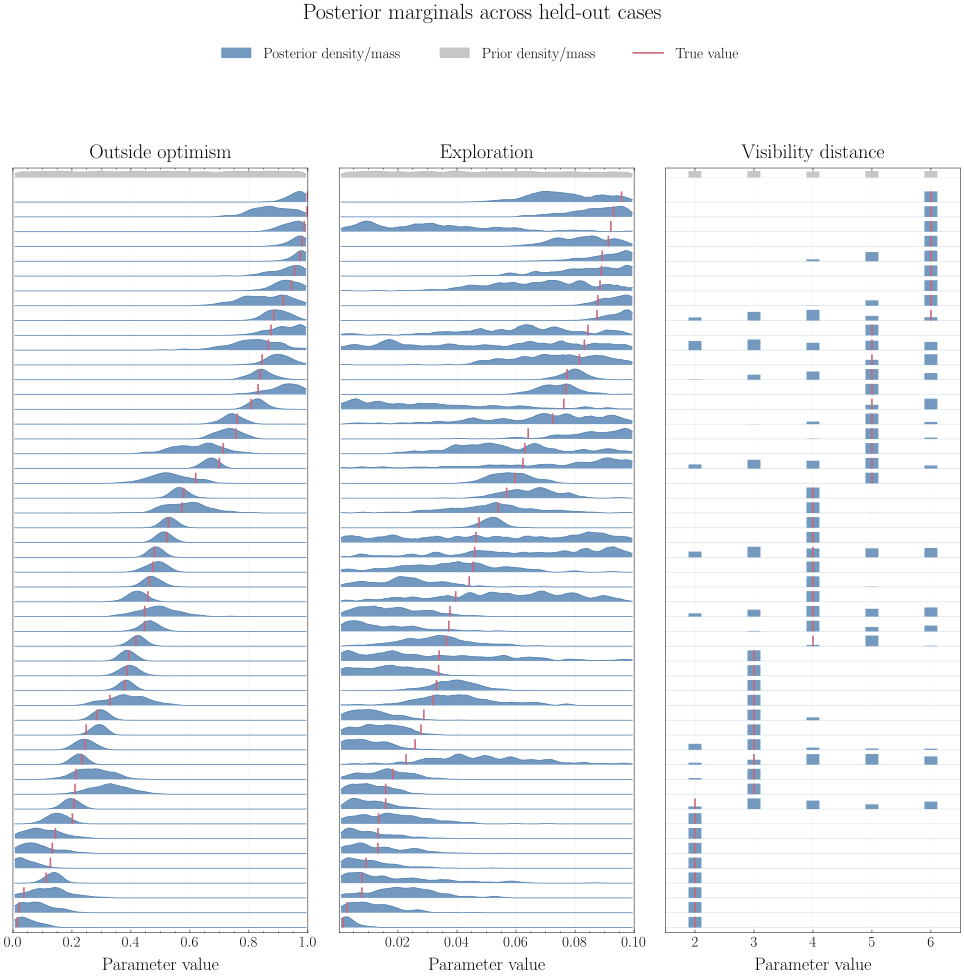

In [11]:
ridgeline_count = min(RIDGELINE_CASES, len(diagnostic_theta))
fig = plot_posterior_ridgelines(
    artifact,
    prior_samples=prior_samples,
    posterior_samples=diagnostic_posterior_samples[:ridgeline_count],
    true_theta=diagnostic_theta[:ridgeline_count],
)
plt.show()

### Recovery by `n_agents`


#### n_agents = 10 (50 displayed cases)

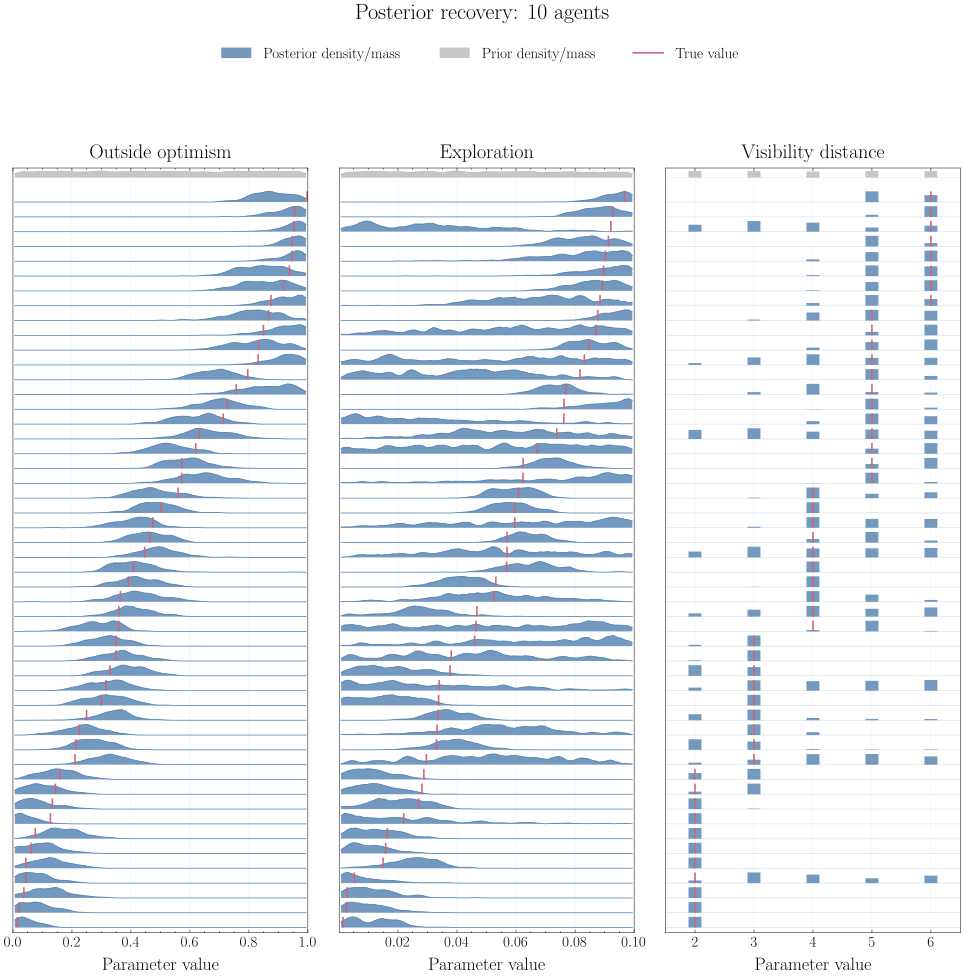

#### n_agents = 50 (50 displayed cases)

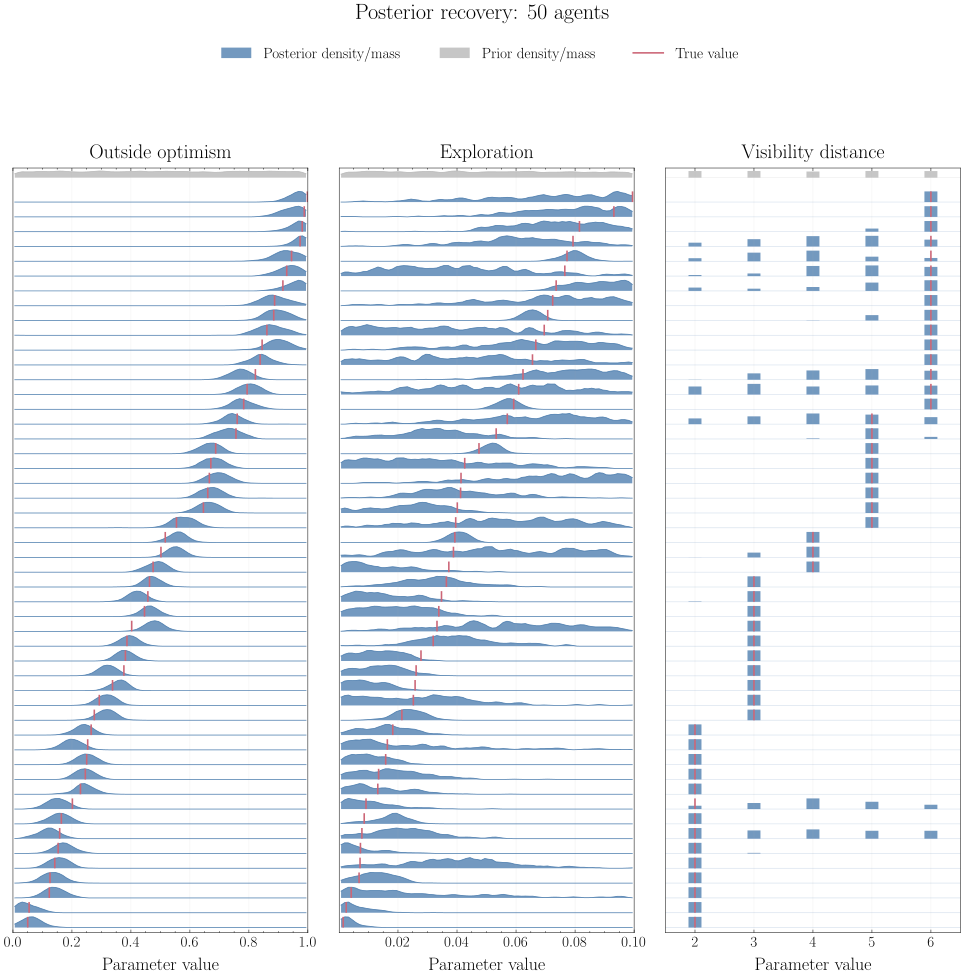

#### n_agents = 100 (50 displayed cases)

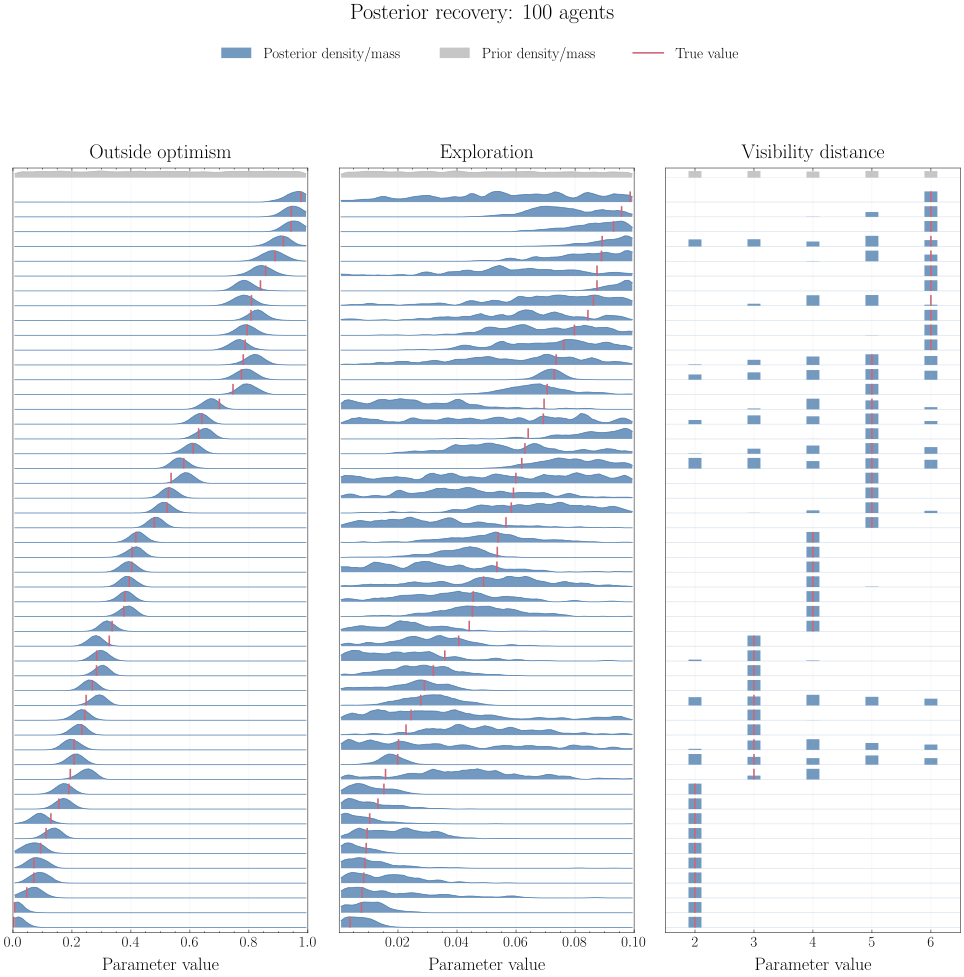

In [12]:
for n_agents_value in n_agent_values:
    group_mask = selected_n_agents == n_agents_value
    group_case_indices = np.flatnonzero(group_mask)[:RIDGELINE_CASES]
    display(
        Markdown(
            f"#### n_agents = {n_agents_value:g} "
            f"({len(group_case_indices)} displayed cases)"
        )
    )
    fig = plot_posterior_ridgelines(
        artifact,
        prior_samples=prior_samples,
        posterior_samples=diagnostic_posterior_samples[group_case_indices],
        true_theta=diagnostic_theta[group_case_indices],
        title=f"Posterior recovery: {n_agents_value:g} agents",
    )
    plt.show()

## 4. Recovery matrix


In [13]:
RECOVERY_MATRIX_LIMIT_PADDING = 0.01
RECOVERY_MATRIX_TICK_BINS = 6


def marginal_posterior_modes(artifact, posterior_samples, bins):
    samples = np.asarray(posterior_samples, dtype=np.float32)
    if samples.ndim != 3 or samples.shape[2] != len(artifact.theta_order):
        raise ValueError(
            "posterior_samples must have shape (case, sample, theta)."
        )
    if bins <= 0:
        raise ValueError("bins must be positive.")

    modes = np.full((samples.shape[0], samples.shape[2]), np.nan, dtype=np.float32)
    for theta_index, name in enumerate(artifact.theta_order):
        for case_index, values in enumerate(samples[:, :, theta_index]):
            if artifact.is_discrete_theta(name):
                categories = artifact.category_values(name)
                probabilities = category_probabilities(values, categories)
                modes[case_index, theta_index] = categories[
                    int(np.argmax(probabilities))
                ]
                continue

            finite = values[np.isfinite(values)]
            if finite.size == 0:
                continue
            if np.all(finite == finite[0]):
                modes[case_index, theta_index] = finite[0]
                continue
            counts, edges = np.histogram(finite, bins=bins)
            mode_bin = int(np.argmax(counts))
            modes[case_index, theta_index] = 0.5 * (
                edges[mode_bin] + edges[mode_bin + 1]
            )
    return modes


def pearson_label(x, y):
    finite = np.isfinite(x) & np.isfinite(y)
    if (
        finite.sum() < 2
        or np.isclose(np.std(x[finite]), 0.0)
        or np.isclose(np.std(y[finite]), 0.0)
    ):
        return "r = n/a"
    return f"r = {np.corrcoef(x[finite], y[finite])[0, 1]:.2f}"


def categorical_accuracy_label(true_values, mode_values):
    finite = np.isfinite(true_values) & np.isfinite(mode_values)
    if not np.any(finite):
        return "accuracy = n/a"
    accuracy = np.mean(np.isclose(true_values[finite], mode_values[finite]))
    return f"accuracy = {accuracy:.2f}"


def categorical_confusion_rates(true_values, mode_values, categories):
    counts = np.zeros((len(categories), len(categories)), dtype=np.int64)
    for true_value, mode_value in zip(true_values, mode_values, strict=True):
        if not np.isfinite(true_value) or not np.isfinite(mode_value):
            continue
        true_match = np.flatnonzero(np.isclose(categories, true_value))
        mode_match = np.flatnonzero(np.isclose(categories, mode_value))
        if true_match.size and mode_match.size:
            counts[int(mode_match[0]), int(true_match[0])] += 1

    column_totals = counts.sum(axis=0, keepdims=True)
    return np.divide(
        counts,
        column_totals,
        out=np.zeros_like(counts, dtype=np.float32),
        where=column_totals > 0,
    )


def plot_categorical_confusion(ax, true_values, mode_values, categories):
    rates = categorical_confusion_rates(true_values, mode_values, categories)
    image = ax.imshow(
        rates,
        vmin=0.0,
        vmax=1.0,
        cmap="Blues",
        aspect="equal",
        origin="lower",
    )
    labels = [f"{value:g}" for value in categories]
    ax.set_xticks(np.arange(len(categories)), labels=labels)
    ax.set_yticks(np.arange(len(categories)), labels=labels)
    ax.minorticks_off()
    ax.tick_params(axis="both", which="both", length=0)
    return image


def plot_recovery_matrix(
    artifact,
    *,
    theta_names,
    true_theta,
    posterior_modes,
    n_agents,
):
    n_agent_values = np.unique(n_agents)
    column_labels = [
        PARAMETER_LABELS.get(
            name,
            name.rsplit(".", 1)[-1].replace("_", " ").capitalize(),
        )
        for name in theta_names
    ]

    continuous_limits = {}
    for theta_index, name in enumerate(theta_names):
        if artifact.is_discrete_theta(name):
            continue
        prior_low = float(artifact.metadata.dataset.prior_low[theta_index])
        prior_high = float(artifact.metadata.dataset.prior_high[theta_index])
        if np.isfinite(prior_low) and np.isfinite(prior_high) and prior_low < prior_high:
            padding = RECOVERY_MATRIX_LIMIT_PADDING * (prior_high - prior_low)
            continuous_limits[theta_index] = (
                prior_low - padding,
                prior_high + padding,
            )
            continue
        true_values = true_theta[:, theta_index]
        mode_values = posterior_modes[:, theta_index]
        finite = np.isfinite(true_values) & np.isfinite(mode_values)
        if not np.any(finite):
            continue
        lower = float(min(true_values[finite].min(), mode_values[finite].min()))
        upper = float(max(true_values[finite].max(), mode_values[finite].max()))
        if lower == upper:
            lower, upper = lower - 0.5, upper + 0.5
        padding = RECOVERY_MATRIX_LIMIT_PADDING * (upper - lower)
        continuous_limits[theta_index] = (lower - padding, upper + padding)

    with plt.rc_context(FIGURE_STYLE):
        n_rows = len(n_agent_values)
        n_cols = len(theta_names)
        panel_spacing = 0.22
        plot_left, plot_right = 0.15, 0.87
        plot_bottom, plot_top = 0.08, 0.89
        figure_height = 3.5 * n_rows
        grid_width = n_cols + (n_cols - 1) * panel_spacing
        grid_height = n_rows + (n_rows - 1) * panel_spacing
        figure_width = (
            figure_height
            * (plot_top - plot_bottom)
            / (plot_right - plot_left)
            * grid_width
            / grid_height
        )
        fig, axes = plt.subplots(
            n_rows,
            n_cols,
            figsize=(figure_width, figure_height),
            sharex="col",
            sharey="col",
            squeeze=False,
        )
        categorical_image = None

        for row_index, n_agents_value in enumerate(n_agent_values):
            group_mask = n_agents == n_agents_value
            for theta_index, name in enumerate(theta_names):
                ax = axes[row_index, theta_index]
                ax.set_box_aspect(1)
                ax.tick_params(axis="x", which="both", labelbottom=True)
                ax.tick_params(axis="y", which="both", labelleft=True)
                true_values = true_theta[group_mask, theta_index]
                mode_values = posterior_modes[group_mask, theta_index]

                if artifact.is_discrete_theta(name):
                    categories = artifact.category_values(name).astype(np.float32)
                    categorical_image = plot_categorical_confusion(
                        ax,
                        true_values,
                        mode_values,
                        categories,
                    )
                    ax.text(
                        0.04,
                        0.96,
                        categorical_accuracy_label(true_values, mode_values),
                        transform=ax.transAxes,
                        va="top",
                        ha="left",
                        fontsize=12,
                        bbox={
                            "facecolor": "white",
                            "alpha": 0.75,
                            "edgecolor": "none",
                        },
                    )
                    continue

                ax.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
                ax.yaxis.set_major_formatter(FormatStrFormatter("%.2f"))
                finite = np.isfinite(true_values) & np.isfinite(mode_values)
                ax.scatter(
                    true_values[finite],
                    mode_values[finite],
                    s=32,
                    alpha=0.35,
                    facecolor="gray",
                    edgecolor="none",
                )
                limits = continuous_limits.get(theta_index)
                if limits is not None:
                    ax.set_xlim(limits)
                    ax.set_ylim(limits)
                    major_ticks = MaxNLocator(
                        nbins=RECOVERY_MATRIX_TICK_BINS
                    ).tick_values(*limits)
                    major_ticks = major_ticks[
                        (major_ticks >= limits[0]) & (major_ticks <= limits[1])
                    ]
                    ax.set_xticks(major_ticks)
                    ax.set_yticks(major_ticks)
                ax.text(
                    0.04,
                    0.96,
                    pearson_label(true_values, mode_values),
                    transform=ax.transAxes,
                    va="top",
                    ha="left",
                    fontsize=12,
                    bbox={
                        "facecolor": "white",
                        "alpha": 0.75,
                        "edgecolor": "none",
                    },
                )
                ax.grid(alpha=0.25)

        fig.subplots_adjust(
            left=plot_left,
            right=plot_right,
            bottom=plot_bottom,
            top=plot_top,
            hspace=panel_spacing,
            wspace=panel_spacing,
        )

        strip_size_inches = 0.35
        strip_left = 0.078
        strip_width = strip_size_inches / figure_width
        for row_index, n_agents_value in enumerate(n_agent_values):
            position = axes[row_index, 0].get_position()
            fig.add_artist(
                Rectangle(
                    (strip_left, position.y0),
                    strip_width,
                    position.height,
                    transform=fig.transFigure,
                    facecolor="0.96",
                    edgecolor="0.75",
                    linewidth=0.8,
                )
            )
            fig.text(
                strip_left + strip_width / 2,
                position.y0 + position.height / 2,
                f"{n_agents_value:g} agents",
                ha="center",
                va="center",
                rotation=90,
                fontsize=15,
                fontweight="bold",
            )

        column_strip_bottom = axes[0, 0].get_position().y1 + 0.012
        column_strip_height = strip_size_inches / figure_height
        for column_index, label in enumerate(column_labels):
            position = axes[0, column_index].get_position()
            fig.add_artist(
                Rectangle(
                    (position.x0, column_strip_bottom),
                    position.width,
                    column_strip_height,
                    transform=fig.transFigure,
                    facecolor="0.96",
                    edgecolor="0.75",
                    linewidth=0.8,
                )
            )
            fig.text(
                position.x0 + position.width / 2,
                column_strip_bottom + column_strip_height / 2,
                label,
                ha="center",
                va="center",
                fontsize=15,
                fontweight="bold",
            )

        if categorical_image is not None:
            colorbar_ax = fig.add_axes([0.93, 0.31, 0.018, 0.46])
            colorbar_ticks = np.linspace(0.0, 1.0, 5)
            colorbar = fig.colorbar(
                categorical_image,
                cax=colorbar_ax,
                ticks=colorbar_ticks,
            )
            colorbar.ax.set_yticklabels(
                [rf"{100 * value:.0f}\%" for value in colorbar_ticks]
            )
            colorbar.ax.set_ylabel(
                "Prediction rate within true category",
                fontsize=15,
                rotation=90,
                ha="center",
                va="bottom",
                multialignment="center",
                labelpad=6,
            )
            colorbar.ax.yaxis.set_label_position("left")
            colorbar.ax.tick_params(labelsize=11, length=0)
            colorbar.ax.minorticks_off()
            colorbar.outline.set_linewidth(0.8)

        fig.supxlabel("True parameter value or category", y=0.02)
        fig.supylabel("Posterior marginal mode or category", x=0.05)
        return fig, axes

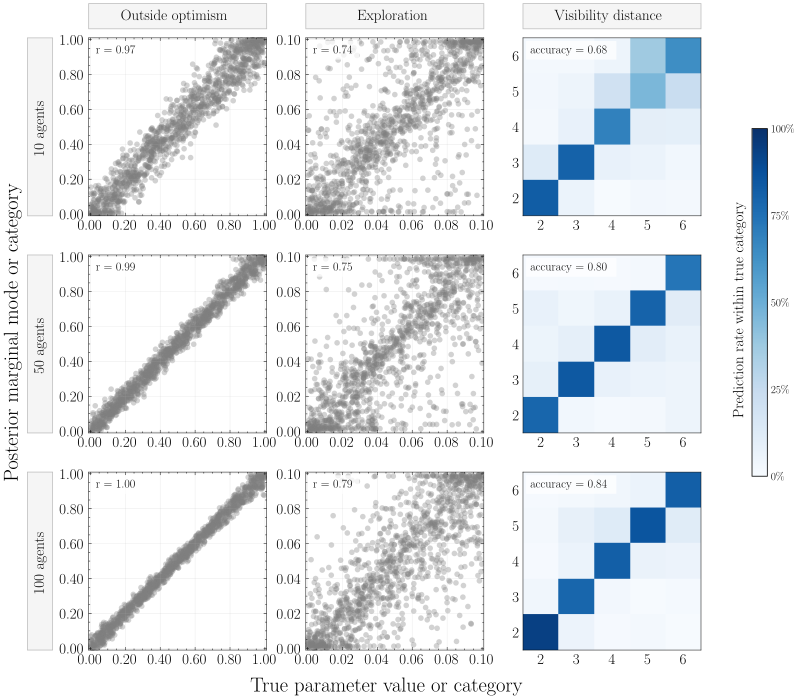

In [14]:
set_matplotlib_formats("svg")

posterior_modes = marginal_posterior_modes(
    artifact,
    diagnostic_posterior_samples,
    MAP_HISTOGRAM_BINS,
)

fig, axes = plot_recovery_matrix(
    artifact,
    theta_names=theta_names,
    true_theta=diagnostic_theta,
    posterior_modes=posterior_modes,
    n_agents=selected_n_agents,
)
plt.show()

In [15]:
run_id = artifact_dir.name
figure_output_dir = project_root / "artifacts" / "figures" / run_id
figure_output_dir.mkdir(parents=True, exist_ok=True)
figure_path = figure_output_dir / "posterior_parameter_recovery_matrix.pdf"
fig.savefig(figure_path, format="pdf", bbox_inches="tight")
print(f"Saved: {figure_path.relative_to(project_root)}")

Saved: artifacts/figures/mnpe-20260806T171531Z/posterior_parameter_recovery_matrix.pdf
